<a href="https://colab.research.google.com/github/sampada-2006/AI-Music-Source-Separation/blob/main/Indian_Classical_Flute_Melody_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Indian Classical Flute Melody Pipeline (Google Colab)

**Purpose:** start from a Demucs-separated flute WAV, extract a continuous F0 contour, normalize pitch relative to tonic Sa, create note-event CSVs, and optionally train a small sequence-model baseline on multiple recordings.

## Dataset choice and important limitation

- **Your own Demucs-separated bansuri WAVs are the primary data** for this project.
- [Medley-solos-DB on Zenodo](https://zenodo.org/records/3464194) is a useful *flute pitch-tracking prototype dataset*: it contains short (~3 s) solo-instrument clips, including a flute class, and is CC BY 4.0. It is **not an Indian classical bansuri dataset** and does not provide tonic, swara, raga, or gamaka labels. The archive is about 7.9 GB.
- [Saraga](https://mtg.github.io/saraga/) can help with Indian classical music analysis and metadata, but do not assume it contains isolated bansuri stems.

A single WAV is enough to test extraction and transposition, **not enough to train a meaningful melody generator**. For the optional LSTM section, collect multiple diverse flute recordings and set the tonic for each recording in `metadata.csv`. Use recordings you have permission to process.

This notebook preserves continuous pitch contours separately from simplified note events because gamakas can be destroyed by overly aggressive note quantization.

## 0. Runtime setup

In Colab, select **Runtime → Change runtime type → CPU or GPU**. GPU is not required for pYIN extraction; it can help the optional neural model.

In [1]:
!pip -q install librosa soundfile pandas numpy matplotlib scipy torch

## 1. Mount Google Drive and set paths

Put your Demucs-separated flute files in `MyDrive/flute_project/audio/`. Name files clearly, e.g. `bansuri_001.wav`.

For the first run, you can upload one WAV directly in the next cell instead.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_DIR = Path('/content/drive/MyDrive/flute_project')
AUDIO_DIR = PROJECT_DIR / 'audio'
OUT_DIR = PROJECT_DIR / 'outputs'
PITCH_DIR = OUT_DIR / 'pitch_tracks'
NOTES_DIR = OUT_DIR / 'notes'

for p in [AUDIO_DIR, OUT_DIR, PITCH_DIR, NOTES_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Audio folder:", AUDIO_DIR)
print("Put WAV files here:", AUDIO_DIR)

Mounted at /content/drive
Audio folder: /content/drive/MyDrive/flute_project/audio
Put WAV files here: /content/drive/MyDrive/flute_project/audio


### Optional: upload one WAV directly

If you already copied your WAV into `AUDIO_DIR`, skip this cell.

In [ ]:
# Uncomment and run if you want to upload a file from your computer:
# from google.colab import files
# uploaded = files.upload()
# for filename, data in uploaded.items():
#     (AUDIO_DIR / filename).write_bytes(data)

## 2. Choose the input file and inspect it

Set `INPUT_WAV` to your separated flute WAV. `SA_HZ` must be the actual tonic frequency of that performance, in Hz. If you do not know Sa, leave it as `None` for now: pitch extraction can still run, but tonic-normalized pitch cannot be trusted until Sa is verified.

Duration: 21.11s | sample rate: 22050 Hz | peak: 0.2472
RMS: 0.03025


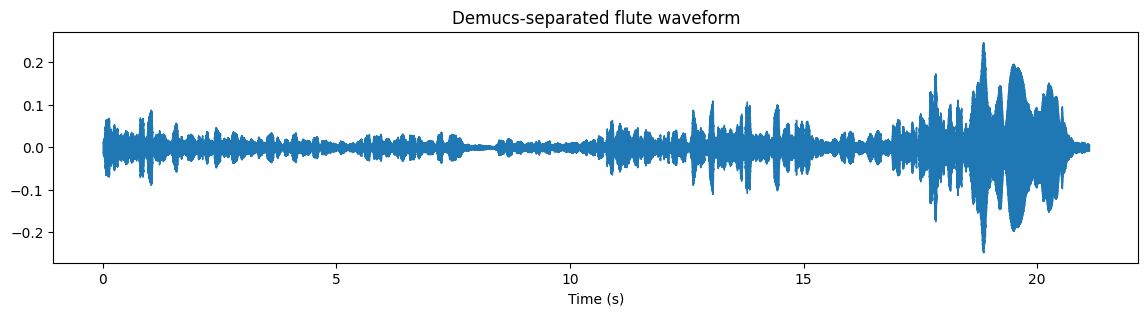

In [7]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

INPUT_WAV = AUDIO_DIR / 'bansuri_001.wav'  # CHANGE THIS
SA_HZ = 451.9  # CHANGE to the actual tonic; set to None if unknown
TARGET_SA_HZ = 240.0  # Example target tonic for transposition demo
SR = 22050
HOP_LENGTH = 220       # ~10 ms at 22.05 kHz
FRAME_LENGTH = 2048

if not INPUT_WAV.exists():
    raise FileNotFoundError(f"Cannot find {INPUT_WAV}. Upload/copy your WAV and update INPUT_WAV.")

y, sr = librosa.load(str(INPUT_WAV), sr=SR, mono=True)
duration = len(y) / sr
print(f"Duration: {duration:.2f}s | sample rate: {sr} Hz | peak: {np.max(np.abs(y)):.4f}")
print(f"RMS: {np.sqrt(np.mean(y**2)):.5f}")

if len(y) == 0 or np.max(np.abs(y)) < 1e-6:
    raise ValueError("Audio is empty or silent.")

plt.figure(figsize=(14, 3))
librosa.display.waveshow(y, sr=sr)
plt.title('Demucs-separated flute waveform')
plt.xlabel('Time (s)')
plt.show()
display(Audio(y, rate=sr))

## 3. Extract F0 using pYIN

pYIN is a reasonable first baseline for predominantly monophonic audio. It can make octave errors, especially if Demucs left other instruments or the flute has noisy/airy sections. Inspect the plot; do not blindly trust the curve.

Saved: /content/drive/MyDrive/flute_project/outputs/pitch_tracks/bansuri_001_pitch.csv


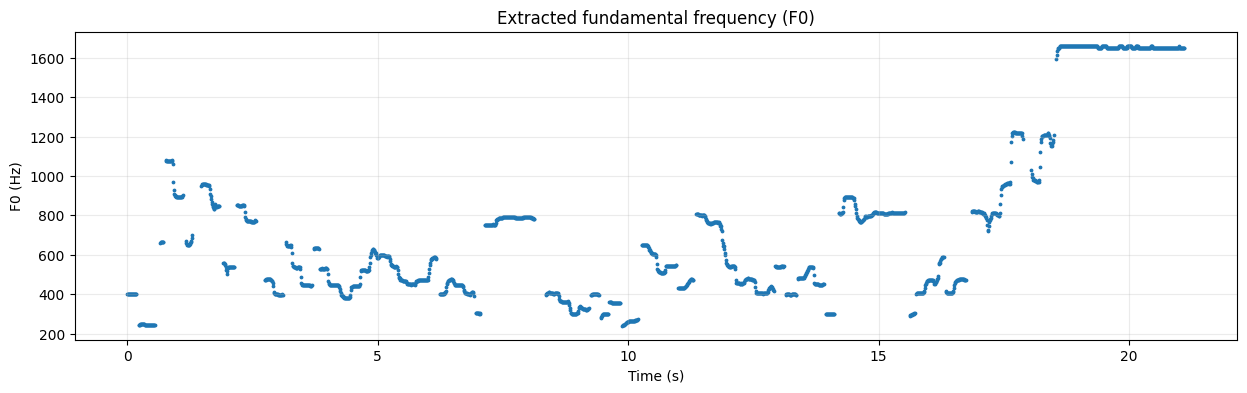

In [8]:
f0, voiced_flag, voiced_prob = librosa.pyin(
    y,
    fmin=librosa.note_to_hz('C3'),  # adjust to your flute's register if needed
    fmax=librosa.note_to_hz('C7'),
    sr=sr,
    frame_length=FRAME_LENGTH,
    hop_length=HOP_LENGTH,
    fill_na=np.nan
)
times = librosa.times_like(f0, sr=sr, hop_length=HOP_LENGTH)

pitch_df = pd.DataFrame({
    'time_s': times,
    'f0_hz': f0,
    'voiced': np.asarray(voiced_flag, dtype=bool),
    'voiced_probability': voiced_prob
})
pitch_path = PITCH_DIR / f'{INPUT_WAV.stem}_pitch.csv'
pitch_df.to_csv(pitch_path, index=False)
print("Saved:", pitch_path)

plt.figure(figsize=(15, 4))
plt.scatter(times, f0, s=3)
plt.xlabel('Time (s)')
plt.ylabel('F0 (Hz)')
plt.title('Extracted fundamental frequency (F0)')
plt.grid(True, alpha=.25)
plt.show()

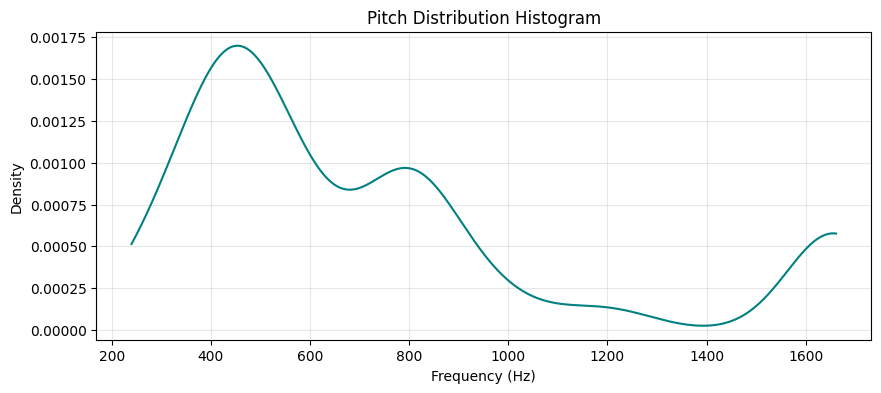

Most prominent pitch peaks detected (Hz):
  -> 450.5 Hz
  -> 451.9 Hz
  -> 453.3 Hz
  -> 454.7 Hz
  -> 456.2 Hz


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Filter out silent/unvoiced pitch frames
valid_f0 = pitch_df.loc[pitch_df['voiced'] & pitch_df['f0_hz'].notna(), 'f0_hz'].values

if len(valid_f0) > 0:
    # Kernel Density Estimation (KDE) to find frequency peaks
    kde = gaussian_kde(valid_f0)
    freq_grid = np.linspace(min(valid_f0), max(valid_f0), 1000)
    density = kde(freq_grid)

    # Find top peak frequencies
    peak_idx = np.argsort(density)[::-1][:5]
    top_freqs = sorted(freq_grid[peak_idx])

    plt.figure(figsize=(10, 4))
    plt.plot(freq_grid, density, color='teal')
    plt.title('Pitch Distribution Histogram')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Density')
    plt.grid(True, alpha=0.3)
    plt.show()

    print("Most prominent pitch peaks detected (Hz):")
    for f in top_freqs:
        print(f"  -> {f:.1f} Hz")

## 4. Convert F0 to cents relative to Sa

Formula: `relative_cents = 1200 * log2(F0 / Sa)`. This representation is invariant to global tuning shifts. Do not estimate Sa as the most common F0 without verification: the melody may not dwell on Sa and ornaments affect pitch statistics.

Saved: /content/drive/MyDrive/flute_project/outputs/pitch_tracks/bansuri_001_normalized_pitch.csv


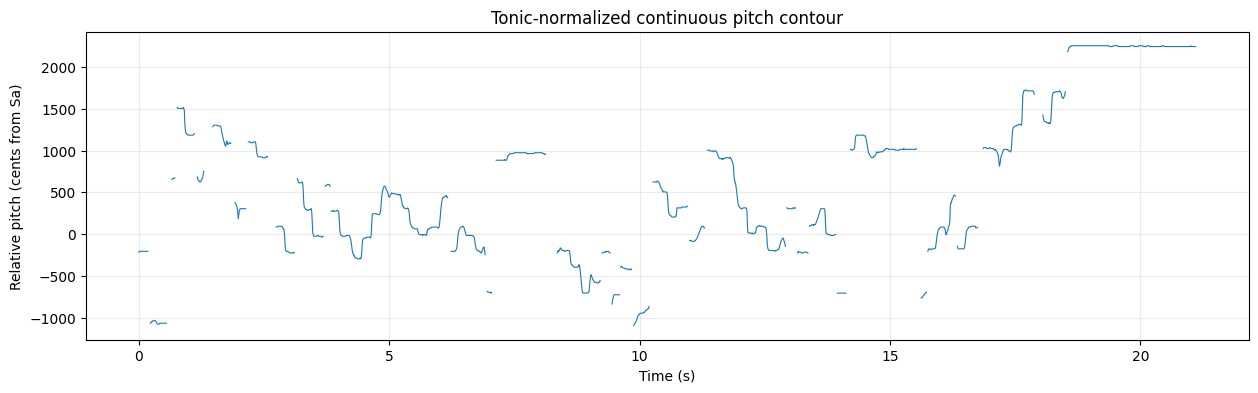

In [9]:
if SA_HZ is not None:
    if SA_HZ <= 0:
        raise ValueError("SA_HZ must be positive.")
    valid = pitch_df['voiced'] & pitch_df['f0_hz'].notna() & (pitch_df['f0_hz'] > 0)
    pitch_df['relative_cents'] = np.nan
    pitch_df.loc[valid, 'relative_cents'] = 1200 * np.log2(
        pitch_df.loc[valid, 'f0_hz'] / SA_HZ
    )
    normalized_path = PITCH_DIR / f'{INPUT_WAV.stem}_normalized_pitch.csv'
    pitch_df.to_csv(normalized_path, index=False)
    print("Saved:", normalized_path)
    plt.figure(figsize=(15, 4))
    plt.plot(pitch_df['time_s'], pitch_df['relative_cents'], linewidth=0.8)
    plt.xlabel('Time (s)')
    plt.ylabel('Relative pitch (cents from Sa)')
    plt.title('Tonic-normalized continuous pitch contour')
    plt.grid(True, alpha=.25)
    plt.show()
else:
    print("SA_HZ is None: F0 extracted, but tonic normalization skipped.")

## 5. Create a first-pass note-event CSV

This is deliberately a **baseline**, not a fully reliable gamaka-aware transcription system. It groups adjacent voiced frames whose pitch stays within a cents tolerance, then merges very short events. Rapid slides/oscillations may be split or smoothed incorrectly. Keep the continuous F0 CSV as the source of truth and manually review event boundaries.

`CHANGE_CENTS` controls how much pitch movement is tolerated within one event. Tune it by inspecting your own recordings.

In [10]:
def make_note_events(df, change_cents=45.0, min_duration_s=0.08):
    d = df.copy().reset_index(drop=True)
    pitch_col = 'relative_cents' if 'relative_cents' in d.columns else 'f0_hz'
    values = d[pitch_col].to_numpy(dtype=float)
    times = d['time_s'].to_numpy(dtype=float)
    voiced = d['voiced'].fillna(False).to_numpy(dtype=bool) & np.isfinite(values)

    # Create frame groups; split at unvoiced frames or when pitch differs
    # from the current group's median by more than threshold.
    groups = []
    current = []
    for i in range(len(d)):
        if not voiced[i]:
            if current:
                groups.append(current)
                current = []
            continue
        if not current:
            current = [i]
            continue
        med = float(np.nanmedian(values[current]))
        if abs(values[i] - med) > change_cents:
            groups.append(current)
            current = [i]
        else:
            current.append(i)
    if current:
        groups.append(current)

    rows = []
    for group in groups:
        start_i, end_i = group[0], group[-1]
        start_t = times[start_i]
        end_t = times[end_i] + (np.median(np.diff(times)) if len(times) > 1 else 0.01)
        dur = end_t - start_t
        if dur < min_duration_s:
            continue
        med_value = float(np.nanmedian(values[group]))
        if pitch_col == 'relative_cents':
            rel = med_value
            abs_hz = float(SA_HZ * 2 ** (rel / 1200)) if SA_HZ is not None else np.nan
        else:
            abs_hz = med_value
            rel = float(1200 * np.log2(abs_hz / SA_HZ)) if SA_HZ else np.nan

        rows.append({
            'start_s': start_t,
            'end_s': end_t,
            'duration_s': dur,
            'median_f0_hz': abs_hz,
            'median_relative_cents': rel,
            'frames': len(group),
            'review_required': True
        })

    return pd.DataFrame(rows)

CHANGE_CENTS = 45.0
MIN_EVENT_SECONDS = 0.08
notes_df = make_note_events(pitch_df, CHANGE_CENTS, MIN_EVENT_SECONDS)
notes_path = NOTES_DIR / f'{INPUT_WAV.stem}_note_events.csv'
notes_df.to_csv(notes_path, index=False)
print("Number of first-pass events:", len(notes_df))
print("Saved:", notes_path)
display(notes_df.head(20))

Number of first-pass events: 78
Saved: /content/drive/MyDrive/flute_project/outputs/notes/bansuri_001_note_events.csv


,start_s,end_s,duration_s,median_f0_hz,median_relative_cents,frames,review_required
0,0.000000,0.189569,0.189569,401.157895,-206.20004,19,True
1,0.229478,0.558730,0.329252,244.105284,-1066.20004,33,True
2,0.768254,0.917914,0.149660,1077.167118,1503.79996,15,True
3,0.927891,1.117460,0.189569,895.382129,1183.79996,19,True
4,1.167347,1.287075,0.119728,655.458084,643.79996,12,True
5,1.476644,1.656236,0.179592,954.119646,1293.79996,18,True
6,1.756009,1.845805,0.089796,850.023969,1093.79996,9,True
7,2.005442,2.145125,0.139683,538.583559,303.79996,14,True
8,2.185034,2.344671,0.159637,852.482483,1098.79996,16,True
9,2.354649,2.574150,0.219501,770.522378,923.79996,22,True


## 6. Optional: approximate swara labels

Only use this as a rough equal-tempered reference. Indian classical intonation is raga- and phrase-dependent; this mapping is **not** a proper shruti/gamaka transcription. A musician-verified raga-specific mapping should replace it in the final model.

In [11]:
def approximate_swara(cents):
    if not np.isfinite(cents):
        return None
    # 12-TET pitch-class labels relative to Sa, nearest semitone.
    semitone = int(np.round(cents / 100.0)) % 12
    labels = {
        0: 'Sa', 1: 'between Sa/komal Re', 2: 'komal Re / Re region',
        3: 'komal Ga / Ga region', 4: 'Ga region', 5: 'Ma region',
        6: 'between Ma/Pa', 7: 'Pa', 8: 'komal Dha / Dha region',
        9: 'Dha region', 10: 'komal Ni / Ni region', 11: 'Ni region'
    }
    return labels[semitone]

if len(notes_df):
    notes_df['approx_swara_12tet'] = notes_df['median_relative_cents'].apply(approximate_swara)
    notes_df.to_csv(notes_path, index=False)
    display(notes_df[['start_s','end_s','duration_s','median_relative_cents','approx_swara_12tet']].head(20))

,start_s,end_s,duration_s,median_relative_cents,approx_swara_12tet
0,0.000000,0.189569,0.189569,-206.20004,komal Ni / Ni region
1,0.229478,0.558730,0.329252,-1066.20004,between Sa/komal Re
2,0.768254,0.917914,0.149660,1503.79996,komal Ga / Ga region
3,0.927891,1.117460,0.189569,1183.79996,Sa
4,1.167347,1.287075,0.119728,643.79996,between Ma/Pa
5,1.476644,1.656236,0.179592,1293.79996,between Sa/komal Re
6,1.756009,1.845805,0.089796,1093.79996,Ni region
7,2.005442,2.145125,0.139683,303.79996,komal Ga / Ga region
8,2.185034,2.344671,0.159637,1098.79996,Ni region
9,2.354649,2.574150,0.219501,923.79996,Dha region


## 7. Transpose the extracted contour to a target Sa

This does not generate a new melody; it renders the **same extracted relative contour** at another tonic. This is the first core test of your project objective.

Saved: /content/drive/MyDrive/flute_project/outputs/pitch_tracks/bansuri_001_target_240Hz.csv


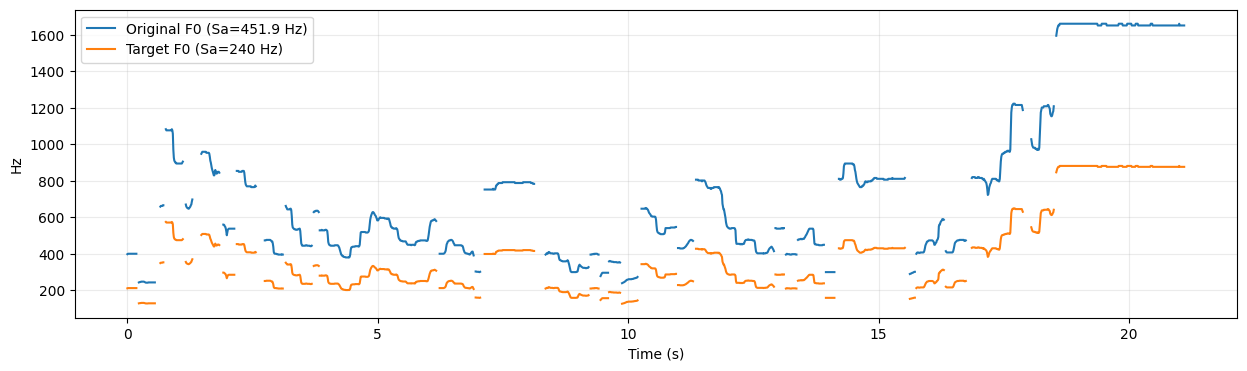

In [12]:
if SA_HZ is None:
    print("Set SA_HZ before transposition.")
else:
    rel = pitch_df['relative_cents'].to_numpy(dtype=float)
    target_f0 = np.full_like(rel, np.nan)
    ok = np.isfinite(rel)
    target_f0[ok] = TARGET_SA_HZ * (2.0 ** (rel[ok] / 1200.0))

    transpose_df = pd.DataFrame({
        'time_s': pitch_df['time_s'],
        'relative_cents': rel,
        'target_sa_hz': TARGET_SA_HZ,
        'target_f0_hz': target_f0
    })
    transposed_path = PITCH_DIR / f'{INPUT_WAV.stem}_target_{TARGET_SA_HZ:g}Hz.csv'
    transpose_df.to_csv(transposed_path, index=False)
    print("Saved:", transposed_path)

    plt.figure(figsize=(15, 4))
    plt.plot(pitch_df['time_s'], pitch_df['f0_hz'], label=f'Original F0 (Sa={SA_HZ:g} Hz)')
    plt.plot(transpose_df['time_s'], transpose_df['target_f0_hz'], label=f'Target F0 (Sa={TARGET_SA_HZ:g} Hz)')
    plt.xlabel('Time (s)')
    plt.ylabel('Hz')
    plt.legend()
    plt.grid(True, alpha=.25)
    plt.show()

# Optional training section: small LSTM baseline

**Only run this after you have multiple diverse flute WAVs.** Training on one short file will mostly memorize it and is not evidence of general melody generation.

Create `metadata.csv` in `AUDIO_DIR` with columns:
- `filename`: WAV filename in the audio folder
- `sa_hz`: verified tonic in Hz for that performance

Example:
```csv
filename,sa_hz
bansuri_001.wav,220.0
bansuri_002.wav,235.0
bansuri_003.wav,240.0
```

Use only isolated flute recordings. The Medley-solos-DB flute clips can help test extraction, but they are short, non-Indian-classical clips and generally lack known Sa. Do not invent tonic labels for them.

In [ ]:
METADATA_CSV = AUDIO_DIR / 'metadata.csv'
if METADATA_CSV.exists():
    metadata = pd.read_csv(METADATA_CSV)
    display(metadata.head())
else:
    print(f"Create {METADATA_CSV} with columns filename,sa_hz before training.")

## 8. Extract normalized pitch sequences for all training recordings

This cell creates frame-level relative-pitch sequences. It removes unvoiced frames and clips extreme values only for model stability. For a research-quality model, retain voicing masks and phrase boundaries instead of simply concatenating distant notes; the simple baseline below is only a first experiment.

In [ ]:
def extract_relative_sequence(wav_path, sa_hz, sr=22050, hop=220):
    audio, _ = librosa.load(str(wav_path), sr=sr, mono=True)
    f0, voiced, prob = librosa.pyin(
        audio,
        fmin=librosa.note_to_hz('C3'),
        fmax=librosa.note_to_hz('C7'),
        sr=sr,
        frame_length=2048,
        hop_length=hop,
        fill_na=np.nan
    )
    valid = np.asarray(voiced, dtype=bool) & np.isfinite(f0) & (f0 > 0)
    rel = 1200 * np.log2(f0[valid] / float(sa_hz))
    # broad guard against pitch-tracking outliers; inspect these clips manually
    rel = rel[np.isfinite(rel)]
    rel = rel[(rel > -2400) & (rel < 3600)]
    return rel.astype(np.float32)

sequences = []
if METADATA_CSV.exists():
    for _, row in metadata.iterrows():
        wav_path = AUDIO_DIR / str(row['filename'])
        sa = float(row['sa_hz'])
        if not wav_path.exists():
            print("Missing:", wav_path)
            continue
        try:
            seq = extract_relative_sequence(wav_path, sa)
            if len(seq) > 100:
                sequences.append(seq)
                print(wav_path.name, "frames:", len(seq))
        except Exception as e:
            print("Failed:", wav_path.name, repr(e))
    print("Usable sequences:", len(sequences))
else:
    print("Training skipped: metadata.csv not found.")

## 9. Train a small LSTM next-frame predictor

This is a proof-of-concept continuous pitch-contour model. It predicts the next relative-pitch frame from the previous frames. It does not explicitly model swaras, tala, raga grammar, or gamaka classes, and it may generate unstable or musically invalid contours. The dataset size and diversity matter far more than increasing the model size.

In [ ]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
WINDOW = 64
BATCH_SIZE = 64
EPOCHS = 15

class WindowDataset(Dataset):
    def __init__(self, seqs, window=64, stride=4):
        self.examples = []
        self.window = window
        for seq in seqs:
            if len(seq) <= window:
                continue
            for start in range(0, len(seq) - window, stride):
                chunk = seq[start:start + window + 1]
                if len(chunk) == window + 1:
                    self.examples.append(chunk)
    def __len__(self):
        return len(self.examples)
    def __getitem__(self, idx):
        a = self.examples[idx]
        x = torch.tensor(a[:-1], dtype=torch.float32).unsqueeze(-1)
        y = torch.tensor(a[1:], dtype=torch.float32).unsqueeze(-1)
        return x, y

class PitchLSTM(nn.Module):
    def __init__(self, hidden=128, layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden,
                            num_layers=layers, batch_first=True,
                            dropout=0.1 if layers > 1 else 0.0)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        z, _ = self.lstm(x)
        return self.head(z)

model = None
loader = None
if len(sequences) >= 3:
    ds = WindowDataset(sequences, window=WINDOW, stride=4)
    if len(ds) > 0:
        loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True)
        model = PitchLSTM().to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        loss_fn = nn.SmoothL1Loss()

        for epoch in range(EPOCHS):
            model.train()
            losses = []
            for xb, yb in loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                loss = loss_fn(pred, yb)
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                losses.append(loss.item())
            print(f"Epoch {epoch+1:02d}/{EPOCHS} | loss={np.mean(losses):.4f}")
        model_path = OUT_DIR / 'relative_pitch_lstm.pt'
        torch.save(model.state_dict(), model_path)
        print("Saved:", model_path)
    else:
        print("Not enough windows. Add longer recordings.")
else:
    print("Training skipped: need at least 3 usable recordings for this basic demo.")

## 10. Generate a relative-pitch contour and apply a target Sa

Autoregressive generation can drift. The example below seeds the model with a short real contour, then predicts future frames. It is a technical demo, not guaranteed novel or musically correct melody generation. Review output and compare against training recordings.

In [ ]:
def generate_contour(model, seed_relative_cents, n_frames=500, temperature=1.0):
    model.eval()
    seed = np.asarray(seed_relative_cents, dtype=np.float32)
    if len(seed) < WINDOW:
        raise ValueError(f"Seed must contain at least {WINDOW} pitch frames.")
    history = list(seed[-WINDOW:])
    generated = []
    with torch.no_grad():
        for _ in range(n_frames):
            x = torch.tensor(history[-WINDOW:], dtype=torch.float32, device=DEVICE).view(1, WINDOW, 1)
            pred = model(x)[0, -1, 0].item()
            # small stochastic perturbation for diversity; tune cautiously
            pred += np.random.normal(0, 2.0 * temperature)
            pred = float(np.clip(pred, -2400, 3600))
            history.append(pred)
            generated.append(pred)
    return np.asarray(generated, dtype=np.float32)

if model is not None and SA_HZ is not None:
    seed_rel = pitch_df['relative_cents'].dropna().to_numpy(dtype=np.float32)
    if len(seed_rel) >= WINDOW:
        generated_rel = generate_contour(model, seed_rel, n_frames=500)
        generated_f0 = TARGET_SA_HZ * (2 ** (generated_rel / 1200.0))
        gen_times = np.arange(len(generated_f0)) * (HOP_LENGTH / SR)

        gen_df = pd.DataFrame({
            'time_s': gen_times,
            'relative_cents': generated_rel,
            'target_sa_hz': TARGET_SA_HZ,
            'generated_f0_hz': generated_f0
        })
        gen_path = OUT_DIR / 'generated_contour_demo.csv'
        gen_df.to_csv(gen_path, index=False)
        print("Saved:", gen_path)

        plt.figure(figsize=(15, 4))
        plt.plot(gen_times, generated_rel)
        plt.xlabel('Time (s)')
        plt.ylabel('Relative pitch (cents from Sa)')
        plt.title('LSTM-generated relative pitch (prototype only)')
        plt.grid(True, alpha=.25)
        plt.show()
    else:
        print("Not enough valid seed pitch frames.")
else:
    print("Generation skipped: train the LSTM and set a verified SA_HZ first.")

## 11. Download results

The key outputs are:
- `outputs/pitch_tracks/*_pitch.csv`: raw pitch contour
- `outputs/pitch_tracks/*_normalized_pitch.csv`: tonic-normalized contour
- `outputs/notes/*_note_events.csv`: first-pass note events
- `outputs/*target*Hz.csv`: contour transposed to a new Sa
- `outputs/relative_pitch_lstm.pt`: optional trained baseline
- `outputs/generated_contour_demo.csv`: optional generated contour

Before reporting results, manually inspect pitch plots and event boundaries. Do not call approximate 12-TET labels final Indian swara annotations.

In [ ]:
print("Outputs folder:", OUT_DIR)
for path in sorted(OUT_DIR.rglob('*')):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR), f"({path.stat().st_size/1024:.1f} KB)")

## Dataset download links

1. **Medley-solos-DB (CC BY 4.0, ~7.9 GB):** [Zenodo record 3464194](https://zenodo.org/records/3464194). Includes flute among eight instrument classes, but is not a bansuri / Indian classical melody corpus.
2. **Saraga Indian Art Music:** [official documentation and access](https://mtg.github.io/saraga/). Useful for Indian classical analysis, but not a guaranteed isolated bansuri dataset.
3. For the actual generative model, prioritize a curated collection of isolated bansuri performances with permission to use them, verified tonic labels, and manual annotations for representative phrases.

**Citation:** Lostanlen, V. & Cella, C.-E. *Deep Convolutional Networks on the Pitch Spiral for Musical Instrument Recognition*, ISMIR 2016. Acknowledge Medley-solos-DB if you use it in academic work.